# 06 · Measure segmentation and investigate mistakes

**Level:** intermediate · **Time:** 60–90 minutes · **Runs:** offline, CPU

**Prerequisites:** NumPy Boolean masks; thresholding and morphology from lessons 01–05.
You can still run this notebook independently: every required function is defined here.

**You will learn to:** derive IoU, Dice, precision, and recall; choose an explicit empty-mask
policy; aggregate multiclass scores; ignore unlabeled pixels; tune a threshold using validation
images; inspect boundary and class-specific errors.

Run from the top. Before each plot, predict what you expect. Record one observation after
each experiment. These tiny synthetic examples teach evaluation mechanics, not real-world accuracy.


In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "learning" / "data.py").is_file()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook inside the complete ImageSegmentationPractical folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (10, 3.5), "image.cmap": "gray",
                     "axes.spines.top": False, "axes.spines.right": False})
print("Project:", PROJECT_ROOT.name)


Project: ImageSegmentationPractical


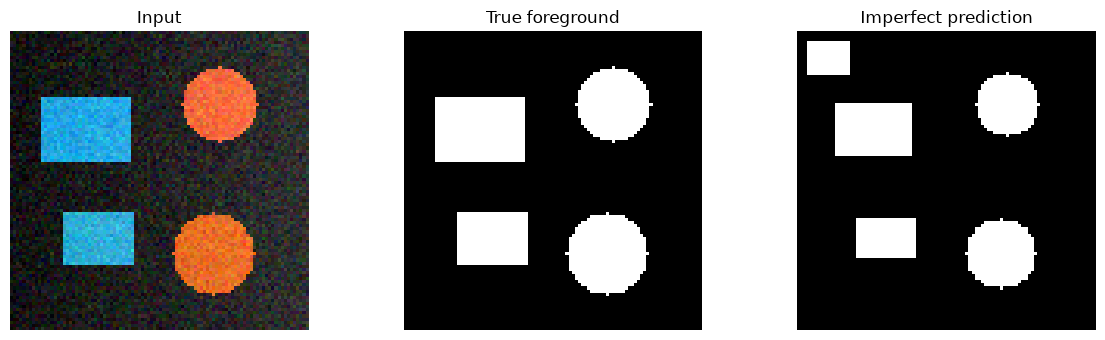

In [2]:
import pandas as pd
from scipy import ndimage as ndi
from skimage.segmentation import find_boundaries
from sklearn.metrics import confusion_matrix, jaccard_score
from learning.data import make_scene, make_dataset, palette_mask

image, semantic, _ = make_scene(seed=16, size=96)
truth = semantic > 0
# Deliberately imperfect prediction: erosion misses edges; a square is a false positive.
prediction = ndi.binary_erosion(truth, iterations=2)
prediction[3:14, 3:17] = True
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, data, title in zip(axes, [image, truth, prediction],
                          ['Input', 'True foreground', 'Imperfect prediction']):
    ax.imshow(data, cmap='gray'); ax.set_title(title); ax.axis('off')
plt.tight_layout(); plt.show()


## Step 1 — Count before using a library

A **true positive (TP)** is foreground in both masks. **FP** is predicted foreground outside
the true object. **FN** is missed foreground. **TN** is correctly predicted background.

\[
\mathrm{IoU}=\frac{TP}{TP+FP+FN},\quad
\mathrm{Dice}=\frac{2TP}{2TP+FP+FN},\quad
\mathrm{precision}=\frac{TP}{TP+FP},\quad
\mathrm{recall}=\frac{TP}{TP+FN}.
\]

IoU penalizes extra and missing regions. Precision asks whether predicted pixels are trustworthy;
recall asks whether true pixels were found. We use hard Boolean masks, not probability maps.


In [3]:
def binary_metrics(y_true, y_pred, empty_overlap=1.0):
    y_true, y_pred = np.asarray(y_true, bool), np.asarray(y_pred, bool)
    if y_true.shape != y_pred.shape:
        raise ValueError('Masks must have identical shapes.')
    if y_true.size == 0:
        raise ValueError('There must be at least one evaluated pixel.')
    tp = int(np.count_nonzero(y_true & y_pred))
    fp = int(np.count_nonzero(~y_true & y_pred))
    fn = int(np.count_nonzero(y_true & ~y_pred))
    tn = int(np.count_nonzero(~y_true & ~y_pred))
    union = tp + fp + fn
    # Precision/recall use zero when their denominator is zero.
    return dict(TP=tp, FP=fp, FN=fn, TN=tn,
                IoU=tp / union if union else empty_overlap,
                Dice=2*tp / (2*tp+fp+fn) if union else empty_overlap,
                precision=tp / (tp+fp) if tp+fp else 0.0,
                recall=tp / (tp+fn) if tp+fn else 0.0,
                accuracy=(tp+tn) / y_true.size)

result = binary_metrics(truth, prediction)
print(pd.Series(result).round(4))
assert np.isclose(result['Dice'], 2*result['IoU']/(1+result['IoU']))
assert np.isclose(result['IoU'], jaccard_score(truth.ravel(), prediction.ravel()))


TP           1378.0000
FP            154.0000
FN            592.0000
TN           7092.0000
IoU             0.6488
Dice            0.7870
precision       0.8995
recall          0.6995
accuracy        0.9191
dtype: float64


## Step 2 — Make undefined cases explicit

If both masks are empty, IoU and Dice contain 0/0. In this lesson their score is **1**:
correctly predicting absence counts as success. Precision/recall with a zero denominator
are **0**. Other projects use 0, NaN, or exclude empty cases; report your policy with your results.
A convention is not a mathematical identity. Never hide the decision by adding an arbitrary epsilon.


In [4]:
empty = np.zeros((8, 8), bool)
single = empty.copy(); single[3, 3] = True
cases = [('both empty', empty, empty), ('false alarm', empty, single),
         ('complete miss', single, empty), ('perfect', single, single)]
table = pd.DataFrame([{'case': name, **binary_metrics(t, p)} for name, t, p in cases])
print(table[['case', 'IoU', 'Dice', 'precision', 'recall']].to_string(index=False))
print('Alternative policy, both empty:', binary_metrics(empty, empty, empty_overlap=np.nan)['IoU'])


         case  IoU  Dice  precision  recall
   both empty  1.0   1.0        0.0     0.0
  false alarm  0.0   0.0        0.0     0.0
complete miss  0.0   0.0        0.0     0.0
      perfect  1.0   1.0        1.0     1.0
Alternative policy, both empty: nan


## Step 3 — Expose the accuracy trap and locate mistakes

A background-only prediction can have impressive accuracy when foreground is rare.
Always report foreground overlap and class-specific scores alongside accuracy.

In the overlay below: **green = TP, red = FP, blue = FN**. Dark pixels are TN.
Judge the location of errors as well as their count: losing a thin connection can matter more
than losing the same number of pixels from a thick interior.


Only 1% foreground, predict all background: {'TP': 0, 'FP': 0, 'FN': 100, 'TN': 9900, 'IoU': 0.0, 'Dice': 0.0, 'precision': 0.0, 'recall': 0.0, 'accuracy': 0.99}


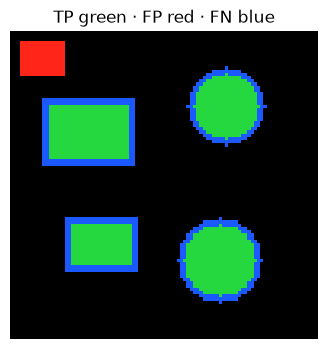

In [5]:
tiny = np.zeros((100, 100), bool); tiny[40:50, 40:50] = True
print('Only 1% foreground, predict all background:', binary_metrics(tiny, np.zeros_like(tiny)))
overlay = np.zeros((*truth.shape, 3), float)
overlay[truth & prediction] = [0.15, 0.85, 0.25]
overlay[~truth & prediction] = [1.0, 0.15, 0.1]
overlay[truth & ~prediction] = [0.1, 0.35, 1.0]
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(overlay); ax.set_title('TP green · FP red · FN blue'); ax.axis('off')
plt.show()


## Step 4 — Multiclass confusion and ignored labels

Each valid pixel has exactly one class: 0 background, 1 disk, 2 rectangle. Rows in our
confusion matrix are truth; columns are prediction. A value of **255** means annotation
unavailable, so remove that pixel from both truth and prediction before counting.

For class *c*: TP is the diagonal entry, FN is the remaining row, FP is the remaining column.
An ignored pixel is not a fourth class and must not silently become background.


Confusion: rows truth / columns prediction
[[6236    0   50]
 [   0  970    0]
 [   0 1000    0]]
 class  support     TP     FP     FN   IoU
     0     6286 6236.0    0.0   50.0 0.992
     1      970  970.0 1000.0    0.0 0.492
     2     1000    0.0   50.0 1000.0 0.000


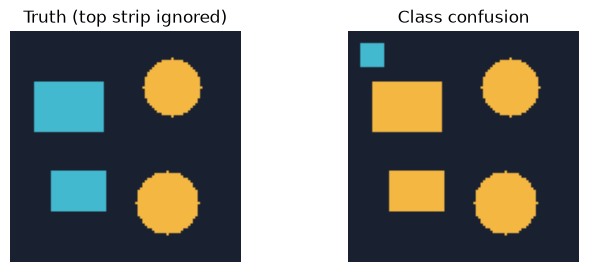

In [6]:
y_true = semantic.copy()
y_true[:10, :] = 255
y_pred = semantic.copy()
y_pred[semantic == 2] = 1  # deliberately confuse rectangles with disks
y_pred[5:15, 5:15] = 2

def multiclass_report(y_true, y_pred, n_classes=3, ignore=255):
    valid = np.asarray(y_true) != ignore
    if not valid.any():
        raise ValueError('No labeled pixels remain.')
    yt, yp = np.asarray(y_true)[valid], np.asarray(y_pred)[valid]
    if not (np.isin(yt, np.arange(n_classes)).all() and
            np.isin(yp, np.arange(n_classes)).all()):
        raise ValueError('Unexpected class ID in evaluated pixels.')
    cm = confusion_matrix(yt, yp, labels=np.arange(n_classes))
    tp = np.diag(cm).astype(float)
    fn, fp = cm.sum(axis=1)-tp, cm.sum(axis=0)-tp
    union = tp+fp+fn
    # Here absent-in-both classes are NaN, excluded from the macro average.
    iou = np.divide(tp, union, out=np.full(n_classes, np.nan), where=union > 0)
    return cm, pd.DataFrame({'class': np.arange(n_classes), 'support': cm.sum(1),
                             'TP': tp, 'FP': fp, 'FN': fn, 'IoU': iou})

cm, class_table = multiclass_report(y_true, y_pred)
print('Confusion: rows truth / columns prediction'); print(cm)
print(class_table.round(3).to_string(index=False))
assert cm.sum() == (y_true != 255).sum()
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
axes[0].imshow(palette_mask(np.where(y_true == 255, 0, y_true)))
axes[0].set_title('Truth (top strip ignored)')
axes[1].imshow(palette_mask(y_pred)); axes[1].set_title('Class confusion')
for ax in axes: ax.axis('off')
plt.show()


## Step 5 — Specify what you averaged

**Macro IoU** gives each included class equal weight. **Micro IoU** sums TP/FP/FN over
classes before dividing, giving frequent classes more influence. Neither is the average of
image-level scores unless explicitly computed that way. State whether background is included.

Class-macro averaging and image-macro averaging answer different questions. The example
below also contrasts equal image weighting with pooling foreground counts across images.


In [7]:
macro_iou = class_table.IoU.mean()  # pandas skips NaN
micro_iou = class_table.TP.sum() / (class_table.TP + class_table.FP + class_table.FN).sum()
print(f'Class macro IoU (background included): {macro_iou:.3f}')
print(f'Class micro IoU (background included): {micro_iou:.3f}')
print(f'Foreground-class macro IoU: {class_table.loc[class_table["class"] > 0, "IoU"].mean():.3f}')
large = np.zeros((40, 40), bool); large[5:35, 5:35] = True
small = np.zeros((40, 40), bool); small[10:14, 10:14] = True
per_image = [binary_metrics(large, large), binary_metrics(small, np.zeros_like(small))]
equal_images = np.mean([r['IoU'] for r in per_image])
pooled = sum(r['TP'] for r in per_image) / sum(r['TP']+r['FP']+r['FN'] for r in per_image)
print(f'Equal image mean IoU: {equal_images:.3f}; pooled foreground IoU: {pooled:.3f}')


Class macro IoU (background included): 0.495
Class micro IoU (background included): 0.774
Foreground-class macro IoU: 0.246
Equal image mean IoU: 0.500; pooled foreground IoU: 0.983


## Step 6 — Tune on validation images, then freeze the decision

We use a fixed, untrained brightness score to keep this lesson focused on evaluation. It is
a bounded **score**, not a calibrated probability. Use validation labels to choose a threshold;
test labels are used only after this choice is frozen. For a learned model, fitting happens on
a separate training split first. Images—not random pixels—are the independent units here.

Predict: lowering the threshold should generally increase recall and reduce precision.
The best threshold depends on your chosen objective; here it is mean per-image foreground IoU.


Frozen threshold: 0.450; validation mean IoU: 1.000


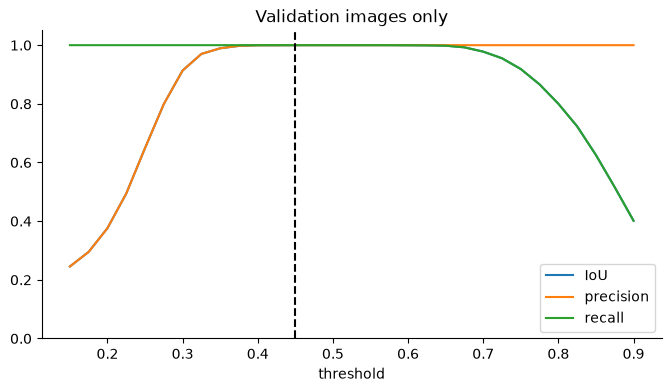

In [8]:
val_images, val_masks = make_dataset(n=8, size=64, seed=400)
test_images, test_masks = make_dataset(n=8, size=64, seed=900)

def foreground_score(images):
    return np.max(images, axis=-1)

val_scores = foreground_score(val_images)
thresholds = np.linspace(0.15, 0.90, 31)
search_rows = []
for threshold in thresholds:
    scores = [binary_metrics(t > 0, s >= threshold) for t, s in zip(val_masks, val_scores)]
    search_rows.append({'threshold': threshold,
                        **{key: np.mean([r[key] for r in scores])
                           for key in ['IoU', 'precision', 'recall']}})
validation_curve = pd.DataFrame(search_rows)
best_row = validation_curve.iloc[validation_curve.IoU.argmax()]
frozen_threshold = float(best_row.threshold)
print(f'Frozen threshold: {frozen_threshold:.3f}; validation mean IoU: {best_row.IoU:.3f}')
ax = validation_curve.plot(x='threshold', y=['IoU', 'precision', 'recall'], figsize=(8, 4))
ax.axvline(frozen_threshold, ls='--', color='black'); ax.set_ylim(0, 1.05)
ax.set_title('Validation images only'); plt.show()


In [9]:
# One final test report: do not change the threshold after reading these results.
test_scores = foreground_score(test_images)
final_rows = [binary_metrics(t > 0, s >= frozen_threshold)
              for t, s in zip(test_masks, test_scores)]
final_report = pd.DataFrame(final_rows)
print('Frozen test mean per-image metrics:')
print(final_report[['IoU', 'Dice', 'precision', 'recall']].mean().round(4))
print('Test image IoUs:', final_report.IoU.round(3).tolist())
print('Eight synthetic images are too few to establish real-world reliability.')


Frozen test mean per-image metrics:
IoU          1.0
Dice         1.0
precision    1.0
recall       1.0
dtype: float64
Test image IoUs: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
Eight synthetic images are too few to establish real-world reliability.


## Step 7 — Look at boundaries

Area overlap can hide a systematic boundary offset. Below we compare contours and compute
an illustrative **boundary F1**: a predicted boundary pixel is correct if it is within a chosen
pixel tolerance of any true boundary pixel; recall reverses that direction. This is not a
replacement for a benchmark's exact boundary protocol. Tolerance has physical meaning only
after accounting for image resolution and pixel spacing.


   tolerance_px  boundary_F1
0             0     0.000000
1             1     0.000000
2             2     0.884396
3             4     0.918728


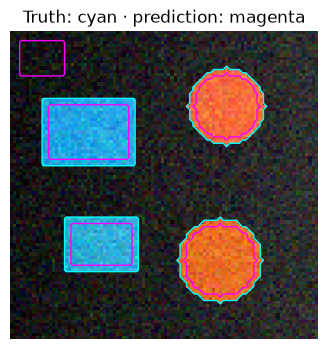

In [10]:
def boundary_f1(y_true, y_pred, tolerance=2):
    bt = find_boundaries(y_true, mode='inner')
    bp = find_boundaries(y_pred, mode='inner')
    if not bt.any() and not bp.any(): return 1.0
    if not bt.any() or not bp.any(): return 0.0
    near_truth = ndi.distance_transform_edt(~bt) <= tolerance
    near_pred = ndi.distance_transform_edt(~bp) <= tolerance
    precision_b = near_truth[bp].mean()
    recall_b = near_pred[bt].mean()
    return 2*precision_b*recall_b/(precision_b+recall_b) if precision_b+recall_b else 0.0

print(pd.DataFrame({'tolerance_px': [0, 1, 2, 4],
                    'boundary_F1': [boundary_f1(truth, prediction, t) for t in [0, 1, 2, 4]]}))
fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(image)
ax.contour(truth, levels=[0.5], colors=['cyan'], linewidths=1)
ax.contour(prediction, levels=[0.5], colors=['magenta'], linewidths=1)
ax.set_title('Truth: cyan · prediction: magenta'); ax.axis('off'); plt.show()


## Your experiments

**Exercise 1 — Hand calculation.** A prediction has TP=8, FP=2, FN=4. Calculate IoU, Dice,
precision, and recall before checking with Python.

<details><summary>Worked solution</summary>

IoU = 8/14 ≈ 0.5714; Dice = 16/22 ≈ 0.7273; precision = 8/10 = 0.8;
recall = 8/12 ≈ 0.6667. Check that Dice = 2×IoU/(1+IoU).

</details>

**Exercise 2 — Change the cost of mistakes.** On the existing validation curve, select the
threshold with the best mean precision among thresholds with mean recall ≥ 0.95.
If no threshold qualifies, report that rather than pretending the constraint was met.
Do not use the current test set to select between objectives.

<details><summary>Worked solution</summary>

```python
eligible = validation_curve[validation_curve.recall >= 0.95]
if eligible.empty:
    print('No candidate meets the recall target.')
else:
    print(eligible.loc[eligible.precision.idxmax()])
```

This changes the decision rule, not the underlying score. For a fresh final comparison,
predeclare the objective and create a new untouched synthetic test split.

</details>

**Exercise 3 — Ignore labels correctly.** Replace all predictions in the ignored strip
with class 2. Does the confusion matrix change? Explain why.

<details><summary>Worked solution</summary>

```python
changed = y_pred.copy()
changed[y_true == 255] = 2
changed_cm, _ = multiclass_report(y_true, changed)
assert np.array_equal(cm, changed_cm)
```

Both arrays are filtered by the truth-derived valid mask, so those predictions cannot
contribute to any evaluated count.

</details>


In [11]:
# Experiment workspace: add your calculations and notes here.
tp, fp, fn = 8, 2, 4
print({'IoU': tp/(tp+fp+fn), 'Dice': 2*tp/(2*tp+fp+fn),
       'precision': tp/(tp+fp), 'recall': tp/(tp+fn)})


{'IoU': 0.5714285714285714, 'Dice': 0.7272727272727273, 'precision': 0.8, 'recall': 0.6666666666666666}


## Common mistakes and completion checklist

- **Dice and IoU disagree unexpectedly:** check the same class, valid pixels, averaging,
  hard threshold, and empty-mask convention were used.
- **Accuracy looks excellent but objects are missing:** inspect foreground IoU and recall.
- **Validation keeps improving while test performance disappoints:** repeated tuning can
  overfit validation too. Use more independent data or grouped cross-validation.
- **Treating every pixel as an independent sample:** uncertainty estimates should usually
  resample independent images, patients, scenes, or acquisition groups, not adjacent pixels.
- **A single mean hides failure:** report per-class/per-image results and representative errors.

Before moving on, confirm you can:

- [ ] Explain every confusion count and derive IoU/Dice.
- [ ] State an empty-mask and ignored-label policy.
- [ ] Distinguish class macro, class micro, and image averaging.
- [ ] Freeze a validation-selected decision before a final test report.
- [ ] Explain why overlap and boundary measures complement each other.

**Continue:** lesson 07 learns pixel classifications from examples.

**Primary references:** [scikit-learn Jaccard/IoU API](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.jaccard_score.html),
[confusion matrix API](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html),
[data leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html),
[scikit-image boundary API](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.find_boundaries).
